## Problem 
A telecom company loses about 26% of its customers. Winning a new customer costs more than keeping an existing one. 

## Goal 
Identify which customers are likely to leave and why, group customers into segments, and recommend retention actions. Success measure: catching as many true churners as possible (recall) without wasting too many offers (precision).

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
df=''
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        df=pd.read_csv(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [2]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df.shape

(7043, 21)

## Getting the info on the dataset

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


We can see there are no null values present from the above info list but the total charges column might have some missing datas as `""` instead of `null` so lets change the data type to int to check and change the value to 0

In [5]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce').fillna(0)

Let's Check for the duplicate values

In [6]:
df['customerID'].duplicated().sum()

np.int64(0)

In [7]:
df['Contract'].value_counts()

Contract
Month-to-month    3875
Two year          1695
One year          1473
Name: count, dtype: int64

## Dropping extra columns
Dropping the customerId column as it will not affect the result of the outcome of the model

In [8]:
df=df.drop(columns='customerID')

## Encoding the Churn column

Using Label Encoding `[Binary encoding]` as it is a classification problem

In [9]:
from sklearn.preprocessing import LabelEncoder
labEnc = LabelEncoder()

In [10]:
df['Churn'] = labEnc.fit_transform(df['Churn'])

In [11]:
df['Churn'].value_counts()

Churn
0    5174
1    1869
Name: count, dtype: int64

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

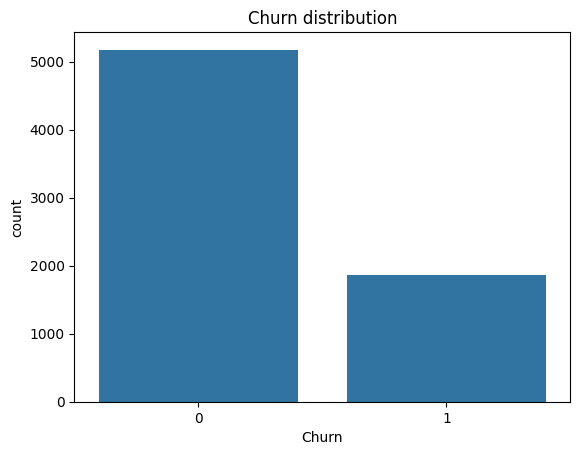

In [13]:
sns.countplot(x='Churn', data=df)
plt.title('Churn distribution')
plt.show()

## Standardization

Changing the values of columns with `No phone service` and `No internet service` to `No`

In [14]:
df['MultipleLines'].value_counts()

MultipleLines
No                  3390
Yes                 2971
No phone service     682
Name: count, dtype: int64

In [15]:
df['MultipleLines'] = df['MultipleLines'].apply(lambda x: 'No' if x == 'No phone service' else x)

In [16]:
df['MultipleLines'].value_counts()

MultipleLines
No     4072
Yes    2971
Name: count, dtype: int64

In [17]:
df['OnlineSecurity'].value_counts()

OnlineSecurity
No                     3498
Yes                    2019
No internet service    1526
Name: count, dtype: int64

In [18]:
cols = ['OnlineSecurity','OnlineBackup','DeviceProtection',
        'TechSupport','StreamingTV','StreamingMovies']
for c in cols:
    df[c] = df[c].apply(lambda x: 'No' if x == 'No internet service' else x)

## Plotting the Churn rate with each of the columns

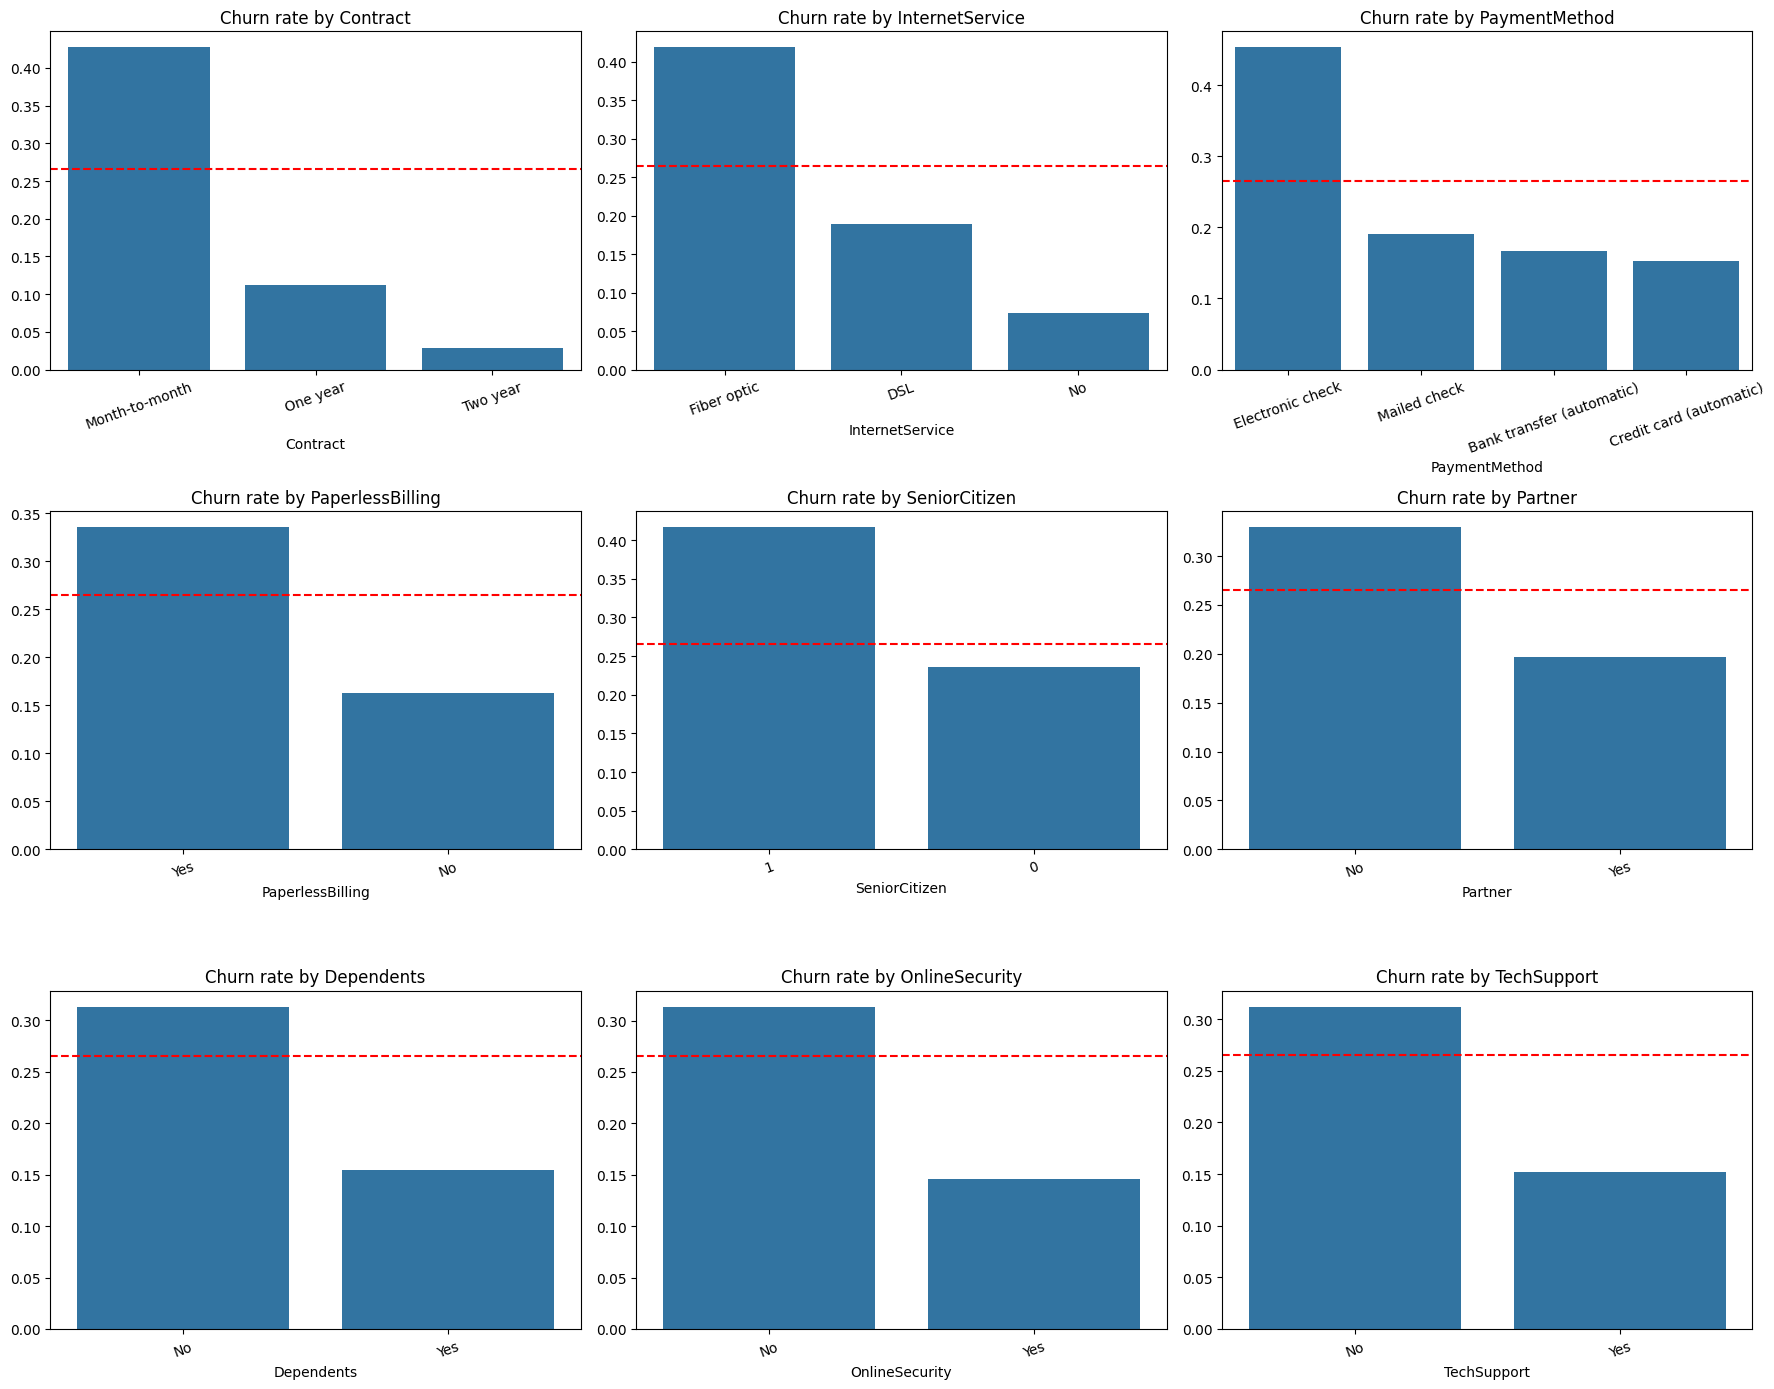

In [19]:
cat_cols = ['Contract', 'InternetService', 'PaymentMethod', 'PaperlessBilling',
            'SeniorCitizen', 'Partner', 'Dependents', 'OnlineSecurity', 'TechSupport']
fig, axes = plt.subplots(3, 3, figsize=(18, 14))
for ax, col in zip(axes.flatten(), cat_cols):
    rate = df.groupby(col)['Churn'].mean().sort_values(ascending=False)
    sns.barplot(x=rate.index.astype(str), y=rate.values, ax=ax)
    ax.axhline(df['Churn'].mean(), color='red', linestyle='--')  # overall churn rate
    ax.set_title(f'Churn rate by {col}')
    ax.tick_params(axis='x', rotation=20)
plt.tight_layout()
plt.show()

## Plotting histogram and box plot against churn rate

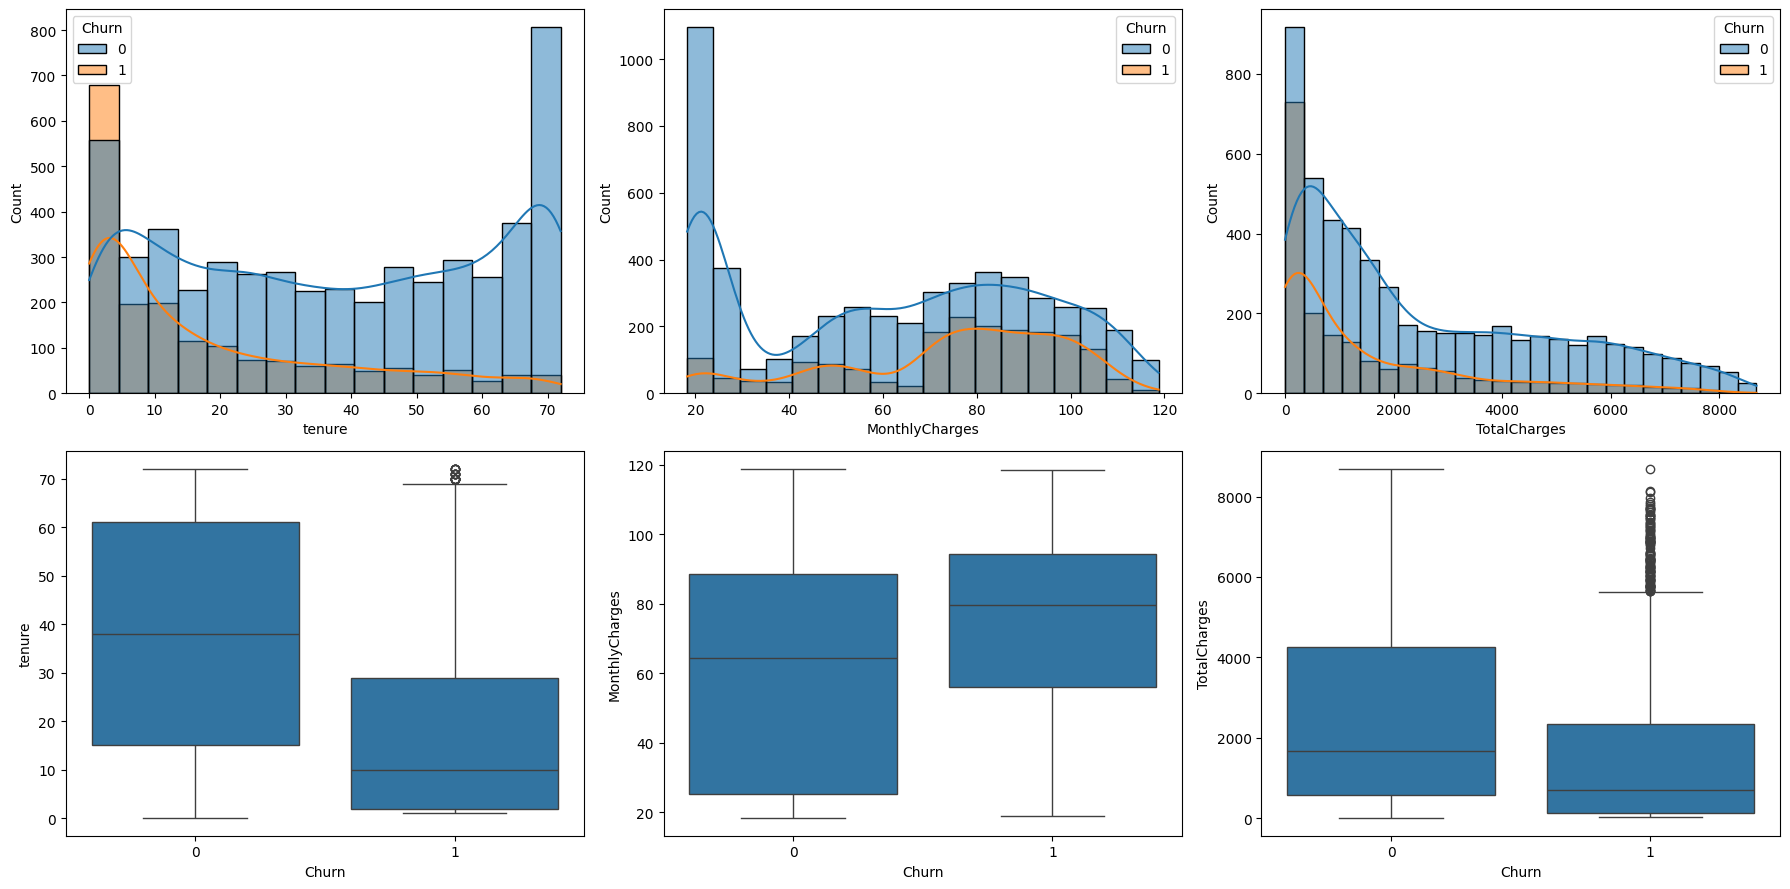

In [20]:
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for i, col in enumerate(num_cols):
    sns.histplot(data=df, x=col, hue='Churn', kde=True, ax=axes[0, i])
    sns.boxplot(data=df, x='Churn', y=col, ax=axes[1, i])
plt.tight_layout()
plt.show()

## Plotting heatmap for the relevance of the columns

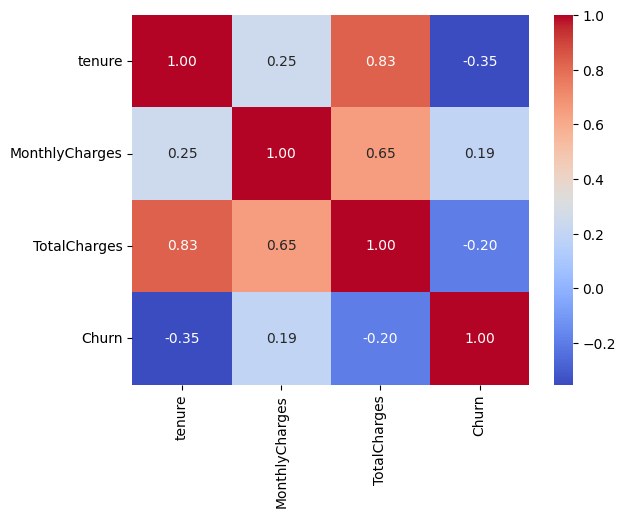

In [21]:
# Correlation heatmap
sns.heatmap(df[num_cols + ['Churn']].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.show()


## Plotting churn rate by tenure bucket

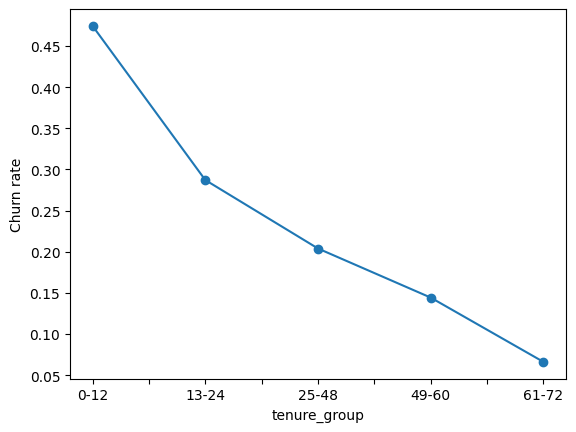

In [22]:
# Churn rate by tenure bucket
df['tenure_group'] = pd.cut(df['tenure'], bins=[-1, 12, 24, 48, 60, 72],
                            labels=['0-12', '13-24', '25-48', '49-60', '61-72'])
df.groupby('tenure_group', observed=True)['Churn'].mean().plot(kind='line', marker='o')
plt.ylabel('Churn rate')
plt.show()

## Segmentation

In [23]:
addon_cols = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
              'TechSupport', 'StreamingTV', 'StreamingMovies','MultipleLines','PhoneService']

In [24]:
df['num_services'] = ((df[addon_cols] == 'Yes').sum(axis=1))
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,tenure_group,num_services
0,Female,0,Yes,No,1,No,No,DSL,No,Yes,...,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0,0-12,1
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,...,No,No,One year,No,Mailed check,56.95,1889.50,0,25-48,3
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,...,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1,0-12,3
3,Male,0,No,No,45,No,No,DSL,Yes,No,...,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0,25-48,3
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,...,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1,0-12,1


## RFM

In [25]:
df['R_score'] = pd.qcut(df['tenure'].rank(method='first'),q=4,labels = [1,2,3,4]).astype(int)
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,tenure_group,num_services,R_score
0,Female,0,Yes,No,1,No,No,DSL,No,Yes,...,No,Month-to-month,Yes,Electronic check,29.85,29.85,0,0-12,1,1
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,...,No,One year,No,Mailed check,56.95,1889.50,0,25-48,3,3
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,...,No,Month-to-month,Yes,Mailed check,53.85,108.15,1,0-12,3,1
3,Male,0,No,No,45,No,No,DSL,Yes,No,...,No,One year,No,Bank transfer (automatic),42.30,1840.75,0,25-48,3,3
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,...,No,Month-to-month,Yes,Electronic check,70.70,151.65,1,0-12,1,1


In [26]:
df['F_score'] = pd.qcut(df['num_services'].rank(method='first'),q=4,labels = [1,2,3,4]).astype(int)
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,tenure_group,num_services,R_score,F_score
0,Female,0,Yes,No,1,No,No,DSL,No,Yes,...,Month-to-month,Yes,Electronic check,29.85,29.85,0,0-12,1,1,1
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,...,One year,No,Mailed check,56.95,1889.50,0,25-48,3,3,2
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,...,Month-to-month,Yes,Mailed check,53.85,108.15,1,0-12,3,1,2
3,Male,0,No,No,45,No,No,DSL,Yes,No,...,One year,No,Bank transfer (automatic),42.30,1840.75,0,25-48,3,3,2
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,...,Month-to-month,Yes,Electronic check,70.70,151.65,1,0-12,1,1,1


In [27]:
df['M_score'] = pd.qcut(df['MonthlyCharges'].rank(method='first'),q=4,labels = [1,2,3,4]).astype(int)
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,tenure_group,num_services,R_score,F_score,M_score
0,Female,0,Yes,No,1,No,No,DSL,No,Yes,...,Yes,Electronic check,29.85,29.85,0,0-12,1,1,1,1
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,...,No,Mailed check,56.95,1889.50,0,25-48,3,3,2,2
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,...,Yes,Mailed check,53.85,108.15,1,0-12,3,1,2,2
3,Male,0,No,No,45,No,No,DSL,Yes,No,...,No,Bank transfer (automatic),42.30,1840.75,0,25-48,3,3,2,2
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,...,Yes,Electronic check,70.70,151.65,1,0-12,1,1,1,3


In [28]:
df['RFM_score'] = df['R_score'] + df['F_score'] + df['M_score']

df['RFM_segment'] = pd.cut(df['RFM_score'], bins=[2, 5, 8, 12],
                           labels=['Low value', 'Mid value', 'High value'])
print(df.groupby('RFM_segment', observed=True).agg(
    customers=('Churn', 'size'),
    churn_rate=('Churn', 'mean'),
    avg_tenure=('tenure', 'mean'),
    avg_services=('num_services', 'mean'),
    avg_monthly=('MonthlyCharges', 'mean')))

             customers  churn_rate  avg_tenure  avg_services  avg_monthly
RFM_segment                                                              
Low value         1895    0.258047   13.216887      1.172559    32.321478
Mid value         2508    0.323764   27.303030      2.759171    61.396152
High value        2640    0.215152   50.934848      5.508712    91.244640


In [29]:
seg = df.groupby('RFM_segment', observed=True)['Churn'].agg(['size', 'mean'])
seg

,size,mean
RFM_segment,,
Low value,1895,0.258047
Mid value,2508,0.323764
High value,2640,0.215152


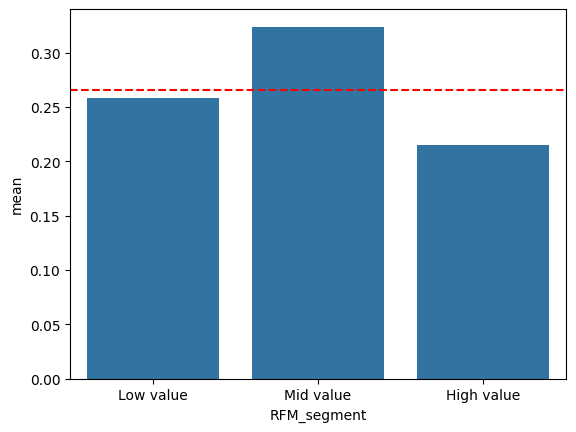

In [30]:
sns.barplot(x=seg.index, y=seg['mean'])
plt.axhline(df['Churn'].mean(), color='red', linestyle='--')
plt.show()

## Let's Split the data into training and test data

In [31]:
from sklearn.model_selection import train_test_split

In [32]:
X = df.drop(columns=['Churn'])
y = df['Churn']

## Changing the data of object types into category for xgboost classifier

In [33]:
cat_cols = X.select_dtypes(include=['object', 'category']).columns
X[cat_cols] = X[cat_cols].astype('category')

In [34]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2, stratify=y, random_state=42)

In [35]:
from xgboost import XGBClassifier

In [36]:
from sklearn.metrics import accuracy_score

## Initialise the xgboost model and train it on the training data

In [37]:
xgb=XGBClassifier(
    n_estimators=300,
    max_depth=7,
    learning_rate=0.05,
    eval_metric='aucpr',
    enable_categorical=True,
    random_state=42
)
xgb.fit(X_train,y_train)
pred=xgb.predict(X_test)
print('Accuracy:',accuracy_score(y_test,pred))

Accuracy: 0.7863733144073811


## Checking the accuracy

Baseline (predict nobody churns): 0.735
              precision    recall  f1-score   support

      Stayed       0.84      0.88      0.86      1035
     Churned       0.61      0.53      0.57       374

    accuracy                           0.79      1409
   macro avg       0.73      0.71      0.71      1409
weighted avg       0.78      0.79      0.78      1409

ROC-AUC: 0.83
PR-AUC : 0.638


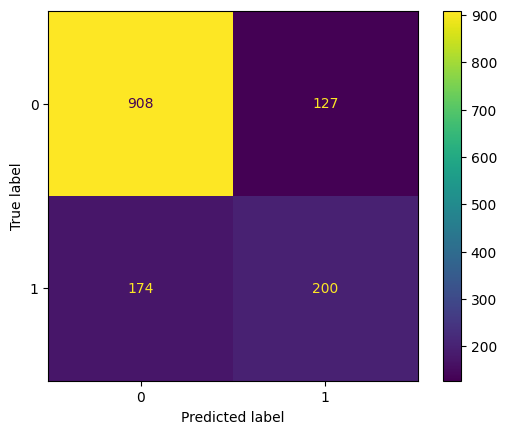

In [38]:
from sklearn.metrics import (classification_report, ConfusionMatrixDisplay,
                             roc_auc_score, average_precision_score)
import matplotlib.pyplot as plt

proba = xgb.predict_proba(X_test)[:, 1]
pred = (proba >= 0.5).astype(int)

print('Baseline (predict nobody churns):', round(1 - y_test.mean(), 3))
print(classification_report(y_test, pred, target_names=['Stayed', 'Churned']))
print('ROC-AUC:', round(roc_auc_score(y_test, proba), 3))
print('PR-AUC :', round(average_precision_score(y_test, proba), 3))

ConfusionMatrixDisplay.from_predictions(y_test, pred)
plt.savefig('/kaggle/working/confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

In [39]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_recall_curve


oof = cross_val_predict(xgb, X_train, y_train, cv=5, method='predict_proba')[:, 1]

prec, rec, thr = precision_recall_curve(y_train, oof)
f2 = 5 * prec * rec / (4 * prec + rec + 1e-9) 
best_thr = thr[np.argmax(f2[:-1])]
print('Chosen threshold:', round(best_thr, 3))

pred_tuned = (proba >= best_thr).astype(int)
print(classification_report(y_test, pred_tuned, target_names=['Stayed', 'Churned']))

Chosen threshold: 0.055
              precision    recall  f1-score   support

      Stayed       0.96      0.47      0.63      1035
     Churned       0.39      0.95      0.56       374

    accuracy                           0.60      1409
   macro avg       0.68      0.71      0.59      1409
weighted avg       0.81      0.60      0.61      1409



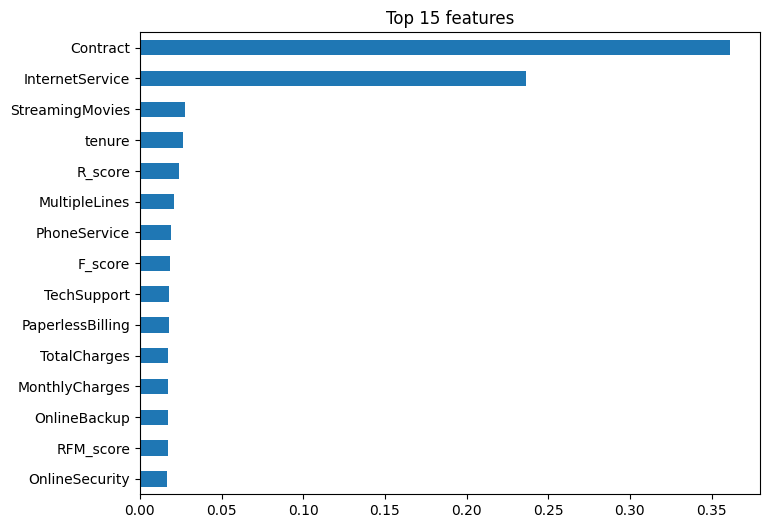

In [40]:
imp = pd.Series(xgb.feature_importances_, index=X_train.columns).sort_values()
imp.tail(15).plot(kind='barh', figsize=(8, 6), title='Top 15 features')
plt.show()

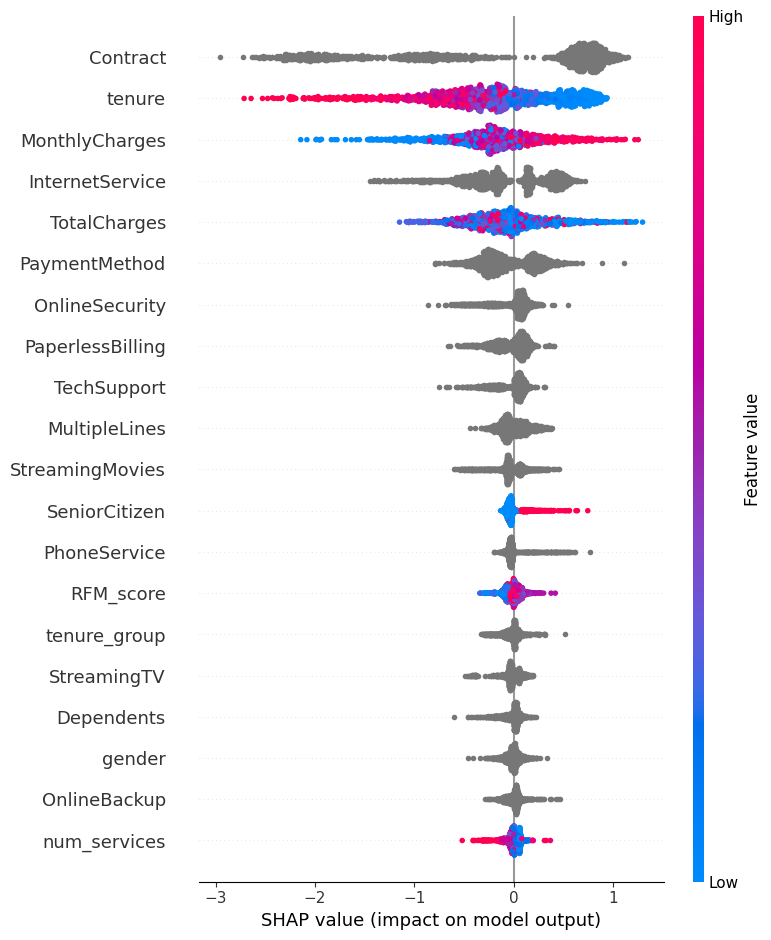

In [41]:
import shap
explainer = shap.TreeExplainer(xgb)
shap_values = explainer(X_test)
shap.summary_plot(shap_values, X_test)

             customers  actual_churn  avg_predicted_risk  avg_tenure  \
RFM_segment                                                            
Low value          373          0.28                0.27       12.48   
Mid value          546          0.31                0.31       28.01   
High value         490          0.20                0.21       51.07   

             avg_monthly  
RFM_segment               
Low value          32.98  
Mid value          60.72  
High value         91.53  


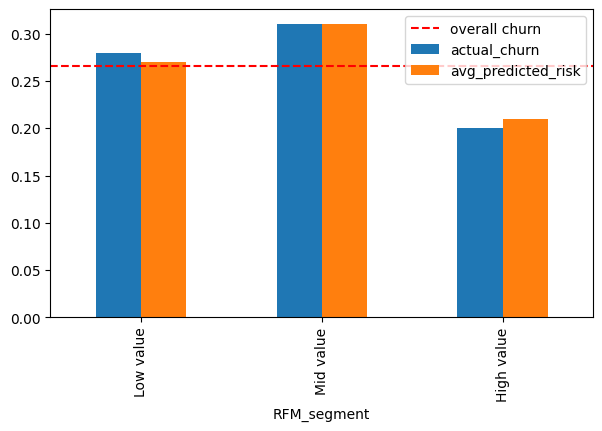

In [42]:
results = df.loc[X_test.index, ['RFM_segment', 'tenure',
                                'Contract', 'MonthlyCharges']].copy()
results['churn_prob'] = proba
results['actual'] = y_test

seg = results.groupby('RFM_segment', observed=True).agg(
    customers=('actual', 'size'),
    actual_churn=('actual', 'mean'),
    avg_predicted_risk=('churn_prob', 'mean'),
    avg_tenure=('tenure', 'mean'),
    avg_monthly=('MonthlyCharges', 'mean')).round(2)
print(seg)

seg[['actual_churn', 'avg_predicted_risk']].plot(kind='bar', figsize=(7, 4))
plt.axhline(y_test.mean(), color='red', linestyle='--', label='overall churn')
plt.legend(); plt.show()

In [43]:
top_pct = 0.20            # contact the riskiest 20%
success_rate = 0.30       # assume 30% of contacted churners are retained
offer_cost = 10           # assumed cost per contacted customer

top = results.sort_values('churn_prob', ascending=False).head(int(top_pct * len(results)))

captured = top['actual'].sum() / results['actual'].sum()
saved_revenue = (top.loc[top['actual'] == 1, 'MonthlyCharges'] * 12 * success_rate).sum()
cost = offer_cost * len(top)

print(f'Contacting the top {top_pct:.0%} riskiest customers catches {captured:.0%} of all churners')
print(f'Estimated revenue retained per year: {saved_revenue:,.0f}')
print(f'Campaign cost: {cost:,.0f}  ->  net: {saved_revenue - cost:,.0f}')

Contacting the top 20% riskiest customers catches 48% of all churners
Estimated revenue retained per year: 50,487
Campaign cost: 2,810  ->  net: 47,677


In [44]:
results['annual_value'] = results['MonthlyCharges'] * 12
results['revenue_at_risk'] = results['churn_prob'] * results['annual_value']

risk_cut = best_thr                       # threshold from the tuning step
value_cut = results['annual_value'].median()

def quadrant(r):
    hi_risk = r['churn_prob'] >= risk_cut
    hi_value = r['annual_value'] >= value_cut
    if hi_risk and hi_value: return 'Priority: retention offer'
    if hi_risk: return 'Low-cost outreach / let go'
    if hi_value: return 'Protect: VIP / loyalty'
    return 'Leave alone'

results['action_group'] = results.apply(quadrant, axis=1)
print(results.groupby('action_group').agg(
    customers=('actual', 'size'),
    actual_churn=('actual', 'mean'),
    revenue_at_risk=('revenue_at_risk', 'sum')).round(2))

                            customers  actual_churn  revenue_at_risk
action_group                                                        
Leave alone                       331          0.03          1998.43
Low-cost outreach / let go        373          0.31         61029.76
Priority: retention offer         532          0.45        263321.37
Protect: VIP / loyalty            173          0.06          3171.25


## Getting all the metrics for the model

In [45]:
from sklearn.metrics import (accuracy_score, recall_score, precision_score,
                             roc_auc_score, average_precision_score)
from sklearn.model_selection import cross_val_score, StratifiedKFold

proba = xgb.predict_proba(X_test)[:, 1]
thr = 0.5
pred = (proba >= thr).astype(int)

print('Rows, cols:', df.shape, '| churn rate:', round(df['Churn'].mean(), 3))
print('Baseline accuracy:', round(1 - y_test.mean(), 3))
print('Threshold:', thr)
print('Accuracy :', round(accuracy_score(y_test, pred), 3))
print('Recall   :', round(recall_score(y_test, pred), 3))
print('Precision:', round(precision_score(y_test, pred), 3))
print('ROC-AUC  :', round(roc_auc_score(y_test, proba), 3))
print('PR-AUC   :', round(average_precision_score(y_test, proba), 3))

cv = StratifiedKFold(5, shuffle=True, random_state=42)
s = cross_val_score(xgb, X, y, cv=cv, scoring='roc_auc')
print('CV ROC-AUC:', round(s.mean(), 3), '+/-', round(s.std(), 3))

print(df.groupby('Contract')['Churn'].mean().round(3))

print(df.groupby('RFM_segment', observed=True).agg(
    customers=('Churn', 'size'), churn_rate=('Churn', 'mean'),
    avg_tenure=('tenure', 'mean'), avg_services=('num_services', 'mean'),
    avg_monthly=('MonthlyCharges', 'mean')).round(2))

res = df.loc[X_test.index, ['MonthlyCharges']].copy()
res['p'] = proba
res['actual'] = y_test
top = res.sort_values('p', ascending=False).head(int(0.2 * len(res)))
print('Share of churners in top 20%:', round(top['actual'].sum() / res['actual'].sum(), 3))
print('Retained revenue (30% success):',
      round((top.loc[top['actual'] == 1, 'MonthlyCharges'] * 12 * 0.30).sum()))

Rows, cols: (7043, 27) | churn rate: 0.265
Baseline accuracy: 0.735
Threshold: 0.5
Accuracy : 0.786
Recall   : 0.535
Precision: 0.612
ROC-AUC  : 0.83
PR-AUC   : 0.638
CV ROC-AUC: 0.83 +/- 0.012
Contract
Month-to-month    0.427
One year          0.113
Two year          0.028
Name: Churn, dtype: float64
             customers  churn_rate  avg_tenure  avg_services  avg_monthly
RFM_segment                                                              
Low value         1895        0.26       13.22          1.17        32.32
Mid value         2508        0.32       27.30          2.76        61.40
High value        2640        0.22       50.93          5.51        91.24
Share of churners in top 20%: 0.479
Retained revenue (30% success): 50487


In [47]:
from sklearn.model_selection import cross_val_predict, StratifiedKFold
import numpy as np

cv = StratifiedKFold(5, shuffle=True, random_state=42)
cust = df[['Churn', 'tenure', 'MonthlyCharges', 'TotalCharges']].copy()
cust['p'] = cross_val_predict(xgb, X, y, cv=cv, method='predict_proba')[:, 1]
cust['clv'] = cust['TotalCharges'] + cust['MonthlyCharges'] * 12
cust['revenue_at_risk'] = cust['MonthlyCharges'] * 12 * cust['p']

hi_risk = cust['p'] >= cust['p'].quantile(0.75)      # riskiest 25%
hi_value = cust['clv'] >= cust['clv'].median()       # CLV above median

cust['group'] = np.select(
    [hi_risk & hi_value, hi_risk & ~hi_value, ~hi_risk & hi_value],
    ['Retention offer', 'Low-cost outreach', 'Early access / VIP'],
    default='Leave alone')

for g in ['Retention offer', 'Low-cost outreach', 'Early access / VIP', 'Leave alone']:
    d = cust[cust['group'] == g]
    print(f"{g}: {len(d):,} | {d['Churn'].mean():.1%} | {d['clv'].mean():,.0f} | {d['revenue_at_risk'].sum():,.0f}")

Retention offer: 615 | 52.0% | 3,940 | 441,149
Low-cost outreach: 1,146 | 64.0% | 1,117 | 681,983
Early access / VIP: 2,907 | 15.1% | 5,284 | 360,429
Leave alone: 2,375 | 15.9% | 1,038 | 157,221


# Conclusion
* Customers on month-to-month contracts churn far more than yearly ones
  - offer a discount to move to a 1-year contract -
  - lowers churn in the highest-risk group.
* Short-tenure, high-bill customers are the riskiest segment
  - onboarding call or bill review in the first 3 months.
* Customers without tech support or online security churn more
   - bundle those add-ons free for a trial period.